### Teoria

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

#### Definição dos Dados

In [36]:
x = np.array([1.0, 2.0, 3.0])
y = np.array([2.0, 4.0, 6.0])
m = len(y)
X = np.column_stack([np.ones(m), x])
beta = np.zeros(X.shape[1])

#### Com laço explícito

In [37]:
b0, b1 = 0.0, 0.0
alpha = 0.1

for t in range(1000):
    y_hat = b0 + b1 * x
    erro = y_hat - y
    grad_b0 = erro.sum() / m
    grad_b1 = (erro * x).sum() / m
    b0 = b0 - alpha * grad_b0
    b1 = b1 - alpha * grad_b1

#### Vetorizado

In [38]:
alpha, epocas, tol = 0.1, 1000, 1e-8
historico = []
trajetoria = []
beta = np.zeros(X.shape[1])

for t in range(epocas):

    trajetoria.append(beta.copy())
    y_hat = X @ beta
    erro = y_hat - y
    custo = (erro @ erro) / (2*m)
    historico.append(custo)
    gradiente = (X.T @ erro) / m
    beta = beta - alpha * gradiente
    if t > 0 and abs(historico[-2] - historico[-1]) < tol:
        break

display(historico)

[np.float64(9.333333333333334),
 np.float64(1.881481481481481),
 np.float64(0.4027621399176953),
 np.float64(0.1087669428440784),
 np.float64(0.04976598147436886),
 np.float64(0.0373901003302839),
 np.float64(0.03427790159668447),
 np.float64(0.03301876767349651),
 np.float64(0.03214250650742168),
 np.float64(0.03135715477657184),
 np.float64(0.03060444696109255),
 np.float64(0.02987247754400559),
 np.float64(0.02915854436168119),
 np.float64(0.028461778781143837),
 np.float64(0.027781683780099747),
 np.float64(0.027117843800821037),
 np.float64(0.026469867017359094),
 np.float64(0.0258373737038817),
 np.float64(0.025219993750998135),
 np.float64(0.02461736600071189),
 np.float64(0.024029137946198376),
 np.float64(0.023454965507964012),
 np.float64(0.022894512829080418),
 np.float64(0.022347452078033694),
 np.float64(0.021813463256825167),
 np.float64(0.021292234013764098),
 np.float64(0.02078345946075487),
 np.float64(0.020286841994955184),
 np.float64(0.019802091124695227),
 np.float

#### Calculando J em grade

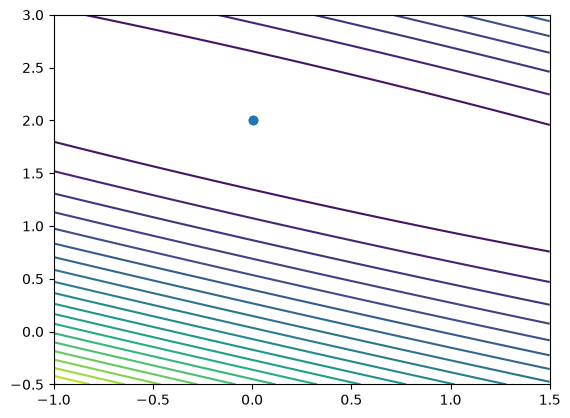

In [39]:
trajetoria = [beta.copy()]
trajetoria.append(beta.copy())
traj = np.array(trajetoria)

B0, B1 = np.meshgrid(np.linspace(-1, 1.5, 200), np.linspace(-0.5, 3, 200))

E = B0[..., None] + B1[..., None] * x - y
J_grade = (E ** 2).sum(axis=-1) / (2 * m)

plt.contour(B0, B1, J_grade, levels=20)
plt.plot(traj[:,0], traj[:,1], 'o-')
plt.show()

#### Animando a Trajetória com FuncAnimation

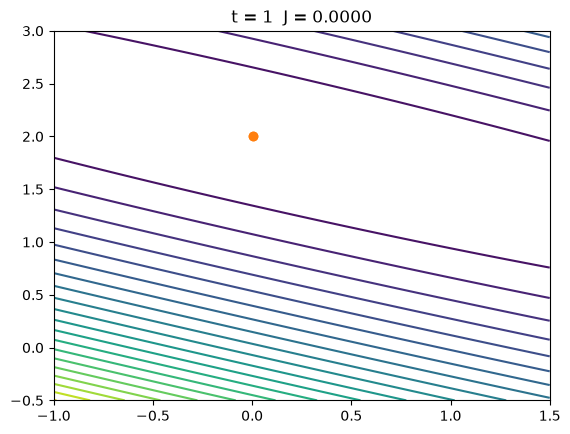

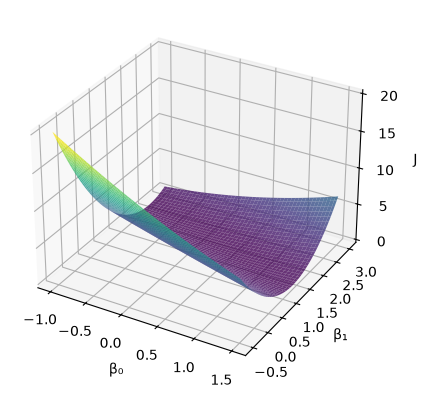

In [40]:

fig, ax = plt.subplots()
ax.contour(B0, B1, J_grade, levels = 20)
caminho, = ax.plot([], [], 'o-', color='C1')

def atualizar(k):
    caminho.set_data(traj[:k + 1, 0], traj[:k + 1, 1])
    J = ((X @ traj[k] - y) ** 2).sum() / (2*m)
    ax.set_title(f't = {k}  J = {J:.4f}')
    return caminho,

anim = FuncAnimation(fig, atualizar, frames=len(traj), interval=100)
anim.save('descida.gif', writer='pillow', fps=10)


fig3d = plt.figure()
ax3d = fig3d.add_subplot(projection='3d')
ax3d.plot_surface(B0, B1, J_grade, cmap='viridis', alpha=0.8)
ax3d.set_xlabel('β₀'); ax3d.set_ylabel('β₁'); ax3d.set_zlabel('J')
plt.show()